In [1]:
import sys

sys.path.insert(0, "..")
import pandas as pd

from chessstyle import fetch, match, profile

gm = pd.read_csv(fetch.DATA / "gm_games.csv")
print(gm.username.nunique(), "GMs,", len(gm), "games")

48 GMs, 19036 games


In [2]:
# 1. Identification accuracy by chunk size (train = earliest 50%)
pd.DataFrame({c: match.identify(gm, chunk=c) for c in (25, 50, 100)}).T

,top1,top5,chance_top5,tests
25,0.144847,0.392758,0.104167,359.0
50,0.167665,0.449102,0.104167,167.0
100,0.228571,0.442857,0.104167,70.0


In [3]:
# 2. Opening ablation
pd.DataFrame({"opening-adjusted": match.identify(gm, 100), "raw": match.identify(gm, 100, by_opening=False)}).T

,top1,top5,chance_top5,tests
opening-adjusted,0.228571,0.442857,0.104167,70.0
raw,0.271429,0.542857,0.104167,70.0


<Axes: title={'center': 'Top-5 accuracy drop when feature is shuffled'}>

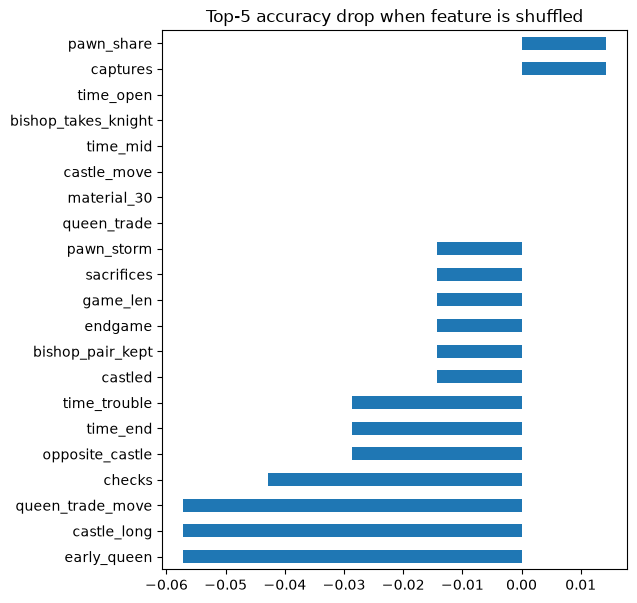

In [4]:
# 3. Permutation importance (top-5 drop when one feature is shuffled across test games)
base = match.identify(gm, 100)["top5"]
imp = pd.Series({f: base - match.identify(gm, 100, drop=f)["top5"] for f in profile.FEATURES}).sort_values()
imp.plot.barh(figsize=(6, 7), title="Top-5 accuracy drop when feature is shuffled")

In [5]:
# 4. Sanity: shuffled GM labels must land at chance
match.identify(gm, 100, shuffle=True)

{'top1': np.float64(0.02857142857142857),
 'top5': np.float64(0.1),
 'chance_top5': 0.10416666666666667,
 'tests': 70}

In [6]:
# Verdict against the pre-registered bar
print("PASS" if base >= 0.30 else "FAIL", f"top-5 @ 100 games = {base:.0%} (bar 30%)")

PASS top-5 @ 100 games = 44% (bar 30%)


In [7]:
# 5. Blitz pool: same identification test (the app matches blitz games only against GM blitz games)
blitz = pd.read_csv(fetch.DATA / "gm_blitz.csv")
print(blitz.username.nunique(), "GMs,", len(blitz), "blitz games")
b = match.identify(blitz, 100)
print(pd.DataFrame({"blitz": b, "blitz, shuffled labels": match.identify(blitz, 100, shuffle=True)}).T)
print("PASS" if b["top5"] >= 0.30 else "FAIL", f"blitz top-5 @ 100 games = {b['top5']:.0%} (bar 30%)")

48 GMs, 23837 blitz games


                            top1      top5  chance_top5  tests
blitz                   0.541667  0.802083     0.104167   96.0
blitz, shuffled labels  0.052083  0.145833     0.104167   96.0
PASS blitz top-5 @ 100 games = 80% (bar 30%)
